Here we plot the number of states versus the temperature.
$$
N_+  = N g\frac{e^{-\beta\varepsilon}}{1+e^{-\beta \varepsilon}}
$$

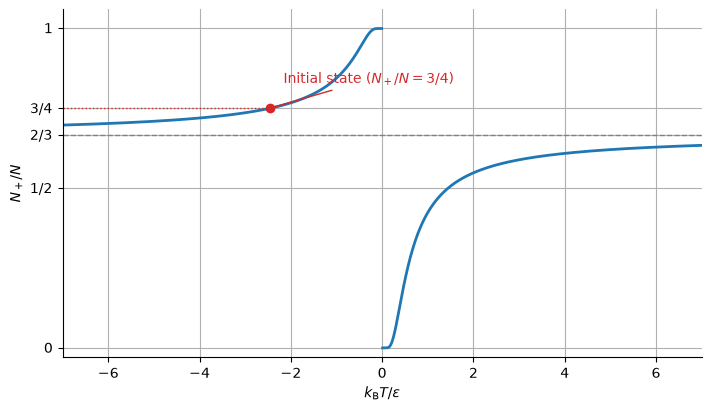

In [6]:
import numpy as np
import matplotlib.pyplot as plt

g = 2
fraction_initial = 0.75

# Dimensionless temperature t = k_B T / epsilon.
# Plot the two branches separately because T = 0 is undefined
# in the population formula.
t_negative = np.linspace(-7, -0.01, 800)
t_positive = np.linspace(0.01, 7, 800)

fraction_negative = g / (g + np.exp(1 / t_negative))
weight_positive = g * np.exp(-1 / t_positive)
fraction_positive = weight_positive / (1 + weight_positive)

t_initial = 1 / np.log(g * (1 - fraction_initial) / fraction_initial)
fraction_infinite = g / (1 + g)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")

ax.plot(t_negative, fraction_negative, color="tab:blue", lw=2)
ax.plot(t_positive, fraction_positive, color="tab:blue", lw=2)

ax.axhline(fraction_infinite, color="0.5", ls="--", lw=1)
ax.hlines(fraction_initial, -7, t_initial, color="tab:red", ls=":", lw=1)
ax.scatter(t_initial, fraction_initial, color="tab:red", zorder=3)
ax.grid()
ax.annotate(
    r"Initial state ($N_+/N=3/4$)",
    xy=(t_initial, fraction_initial),
    xytext=(10, 18),
    textcoords="offset points",
    color="tab:red",
    arrowprops={"arrowstyle": "-", "color": "tab:red"},
)

ax.set(
    xlabel=r"$k_{\mathrm{B}}T/\varepsilon$",
    ylabel=r"$N_+/N$",
    xlim=(-7, 7),
    ylim=(-0.03, 1.06),
)
ax.set_yticks(
    [0, 0.5, fraction_infinite, fraction_initial, 1],
    labels=[r"$0$", r"$1/2$", r"$2/3$", r"$3/4$", r"$1$"],
)
ax.spines[["top", "right"]].set_visible(False)

fig.savefig("excited_state_fraction.svg", dpi=300, bbox_inches="tight")
plt.show()

And the entropy

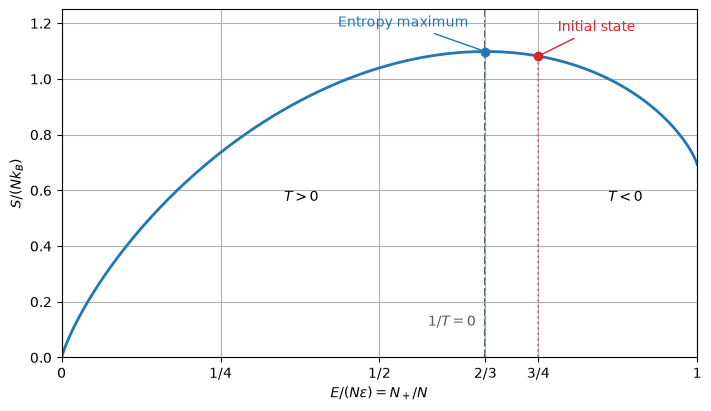

In [12]:
import numpy as np
import matplotlib.pyplot as plt

g = 2
x_max = g / (1 + g)
x_initial = 0.75
x_flip = g / (1 + g)


def entropy_per_particle(x):
    """Return S/(N k_B) for 0 < x < 1."""
    return -x * np.log(x) - (1 - x) * np.log1p(-x) + x * np.log(g)

x = np.linspace(0, 1, 1001)
s = np.empty_like(x)
s[1:-1] = entropy_per_particle(x[1:-1])
s[0], s[-1] = 0, np.log(g)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(x, s, color="tab:blue", lw=2)
ax.grid()

for position, label, color, offset in [
    (x_max, "Entropy maximum", "tab:blue", (-12, 18)),
    (x_initial, "Initial state", "tab:red", (14, 18)),
]:
    height = entropy_per_particle(position)
    ax.vlines(position, 0, height, color=color, ls=":", alpha=0.5)
    ax.scatter(position, height, color=color, zorder=3)
    ax.annotate(
        label, (position, height), xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left",
        color=color, arrowprops={"arrowstyle": "-", "color": color},
    )

ax.text(0.35, 0.56, r"$T>0$")
ax.text(0.86, 0.56, r"$T<0$")
ax.set(
    xlabel=r"$E/(N\varepsilon)=N_+/N$",
    ylabel=r"$S/(N k_{B})$",
    xlim=(0, 1),
    ylim=(0, 1.25),
)
ax.set_xticks(
    [0, 0.25, 0.5, x_max, x_initial, 1],
    ["0", "1/4", "1/2", "2/3", "3/4", "1"],
)
ax.axvline(
    x_flip,
    color="0.35",
    linestyle="--",
    linewidth=1.4,
    zorder=1,
)
ax.text(
    x_flip - 0.015,
    0.08,
    r"$1/T=0$",
    transform=ax.get_xaxis_transform(),
    ha="right",
    va="bottom",
    color="0.35",
)
fig.savefig("entropy_degenerate_two_level.svg", dpi = 300, bbox_inches="tight")
plt.show()